In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.19.0


In [2]:
# Load the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Check the shape of the data
# 60,000 images, each 28x28 pixels
print(f"Training data shape: {x_train.shape}")
# 10,000 images, each 28x28 pixels
print(f"Test data shape: {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


In [3]:
# Normalize the pixel values from 0-255 to 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

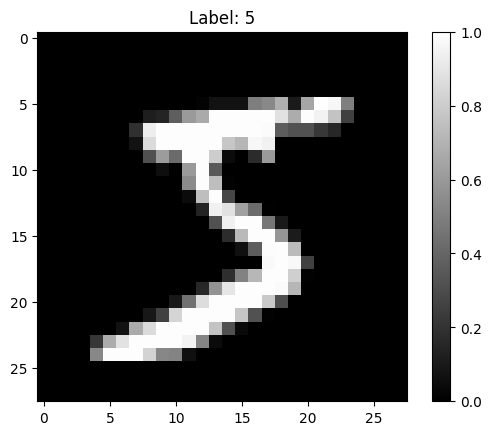

In [4]:
# Display the first image in the training set
plt.figure()
plt.imshow(x_train[0], cmap='gray') # Show image in grayscale
plt.colorbar()
plt.title(f"Label: {y_train[0]}")
plt.show()

In [5]:
model = keras.Sequential([
    # Flattens the 28x28 image into a 1D array of 784 pixels
    keras.layers.Flatten(input_shape=(28, 28)),

    # A "hidden" layer with 128 neurons
    keras.layers.Dense(128, activation='relu'),

    # A dropout layer to prevent overfitting
    keras.layers.Dropout(0.2),

    # The "output" layer with 10 neurons (one for each digit 0-9)
    # Softmax gives us a probability for each digit
    keras.layers.Dense(10, activation='softmax')
])

# You can print a summary of the model
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
# Train the model
# An "epoch" is one full pass over the entire training dataset.
print("Starting training...")
history = model.fit(x_train, y_train,
                    epochs=10,
                    validation_data=(x_test, y_test))
print("Training finished!")

Starting training...
Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8587 - loss: 0.4824 - val_accuracy: 0.9583 - val_loss: 0.1382
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9549 - loss: 0.1545 - val_accuracy: 0.9689 - val_loss: 0.1040
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9675 - loss: 0.1075 - val_accuracy: 0.9727 - val_loss: 0.0886
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9729 - loss: 0.0899 - val_accuracy: 0.9752 - val_loss: 0.0814
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9781 - loss: 0.0682 - val_accuracy: 0.9765 - val_loss: 0.0761
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9817 - loss: 0.0594 - val_accuracy: 0.9789 - val_loss: 0.0694
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9817 - loss: 0.0563 - val_accuracy: 0.9800 - val_loss: 0.0684
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9

In [8]:
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)

print(f'\nTest accuracy: {test_acc * 100:.2f}%')

313/313 - 1s - 2ms/step - accuracy: 0.9788 - loss: 0.0744

Test accuracy: 97.88%


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


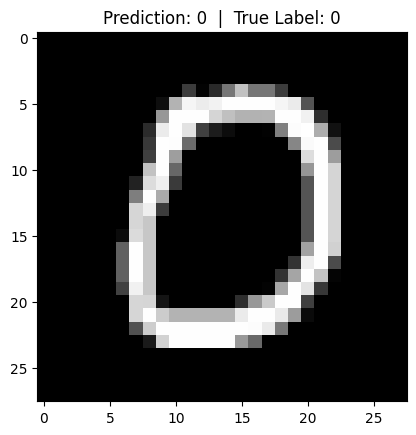

Model's full prediction (probabilities for 0-9):
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [9]:
# Make predictions on the test set
predictions = model.predict(x_test)

# --- Test a single image ---
# You can change this index to see other images
image_index = 10

# Get the prediction array for our chosen image
single_prediction = predictions[image_index]

# Find the digit (0-9) with the highest probability
predicted_digit = np.argmax(single_prediction)

# Get the true label
true_digit = y_test[image_index]

# Display the image
plt.imshow(x_test[image_index], cmap='gray')
plt.title(f"Prediction: {predicted_digit}  |  True Label: {true_digit}")
plt.show()

print(f"Model's full prediction (probabilities for 0-9):\n {single_prediction.round(3)}")

In [10]:
# Install the Google Text-to-Speech library
!pip install gTTS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 7.0 MB/s eta 0:00:00
  Attempting uninstall: click
    Found existing installation: click 8.3.0
    Uninstalling click-8.3.0:
      Successfully uninstalled click-8.3.0


In [11]:
from gtts import gTTS
from IPython.display import Audio, display

# 1. Convert the predicted digit (an integer) to a string
# (This assumes 'predicted_digit' variable is from the previous cell)
text_to_speak = str(predicted_digit)

print(f"Generating audio for the number: {text_to_speak}")

# 2. Create the gTTS object
# 'lang="en"' specifies the language as English
tts = gTTS(text=text_to_speak, lang='en')

# 3. Save the audio to a file
filename = "prediction_audio.mp3"
tts.save(filename)

# 4. Display an audio player in the Colab output
print(f"Successfully saved audio to {filename}")
display(Audio(filename, autoplay=False))

Generating audio for the number: 0
Successfully saved audio to prediction_audio.mp3
